# Cairn Outdoor: recommend products and rethink the catalogue, a solution

In [ ]:
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import spacy
from sklearn.cluster import DBSCAN
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from wordcloud import WordCloud
import plotly.io as pio
import plotly.graph_objects as go
pio.templates["course"] = go.layout.Template(layout_colorway=["#3B47C4", "#E4572E", "#2E7D4F", "#F2C14E", "#8E7CC3", "#4BA3C3", "#111111", "#999999"])
pio.templates.default = "plotly_white+course"

## Preprocessing

In [ ]:
catalog = pd.read_csv("data/cairn_outdoor_catalog.csv")
print(f"{len(catalog)} products")
print(catalog["category"].value_counts().to_string())
print()
print(catalog.loc[0, "name"], "->", catalog.loc[0, "description"])

304 products
category
Tops           57
Bottoms        57
Camping        57
Bags           38
Footwear       38
Jackets        38
Accessories    19

Merino Crew -> A merino wool base layer that regulates your temperature and does not hold odours. Flatlock seams avoid chafing under a backpack. Odour control keeps it fresh on multi-day trips. Fair Trade Certified sewing. Ski touring guides take it on every winter trip. Great for skiing, snowshoeing and winter hikes. Bring it back to any store when it is worn out: we repair it or recycle it.


In [ ]:
nlp = spacy.load("en_core_web_sm", disable=["parser", "ner"])

def clean(text):
    text = re.sub(r"[^a-z ]", " ", text.lower())          # letters only
    return " ".join(t.lemma_ for t in nlp(text) if not t.is_stop and len(t.text) > 2)

catalog["clean"] = [clean(t) for t in catalog["description"]]
catalog[["description", "clean"]].head(3)

,description,clean
0,A merino wool base layer that regulates your t...,merino wool base layer regulate temperature ho...
1,A small hydration pack for trail runs and fast...,small hydration pack trail run fast hike pack ...
2,A light trail running shoe with an aggressive ...,light trail running shoe aggressive outsole mu...


In [ ]:
vectorizer = TfidfVectorizer(min_df=2)
X = vectorizer.fit_transform(catalog["clean"])
words = vectorizer.get_feature_names_out()
print(f"TF-IDF matrix: {X.shape[0]} products x {X.shape[1]} words, {1 - X.nnz / np.prod(X.shape):.1%} zeros")

TF-IDF matrix: 304 products x 478 words, 92.5% zeros


## Part 1: groups of similar products

DBSCAN with the cosine distance ($1 -$ cosine similarity). We try a grid of `eps` and `min_samples` and look at the number of clusters and the share of noise.

In [ ]:
rows = []
for eps in [0.4, 0.45, 0.5, 0.55, 0.6, 0.65]:
    for min_samples in [3, 5]:
        labels = DBSCAN(eps=eps, min_samples=min_samples, metric="cosine").fit_predict(X)
        rows.append({"eps": eps, "min_samples": min_samples,
                     "clusters": labels.max() + 1, "noise": round(np.mean(labels == -1), 2)})
pd.DataFrame(rows).set_index(["eps", "min_samples"]).unstack()

clusters     noise      
min_samples        3   5     3     5
eps                                 
0.40              32  17  0.23  0.64
0.45              22  20  0.08  0.37
0.50              15  16  0.02  0.05
0.55              14  14  0.00  0.01
0.60               7   7  0.00  0.00
0.65               4   4  0.00  0.00

**What this shows:** a small `eps` gives many clusters but labels many products as noise; a large `eps` merges everything into a few big clusters. We keep the setting that gives 10 to 20 clusters with little noise (below).

In [ ]:
dbscan = DBSCAN(eps=0.5, min_samples=5, metric="cosine")
catalog["cluster"] = dbscan.fit_predict(X)
print(f"{catalog.cluster.max() + 1} clusters, {np.mean(catalog.cluster == -1):.0%} of the products are noise")
catalog["cluster"].value_counts().sort_index().to_frame("products").T

16 clusters, 5% of the products are noise


cluster,-1,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
products,16,27,19,19,18,16,19,18,19,19,19,19,19,17,18,17,5


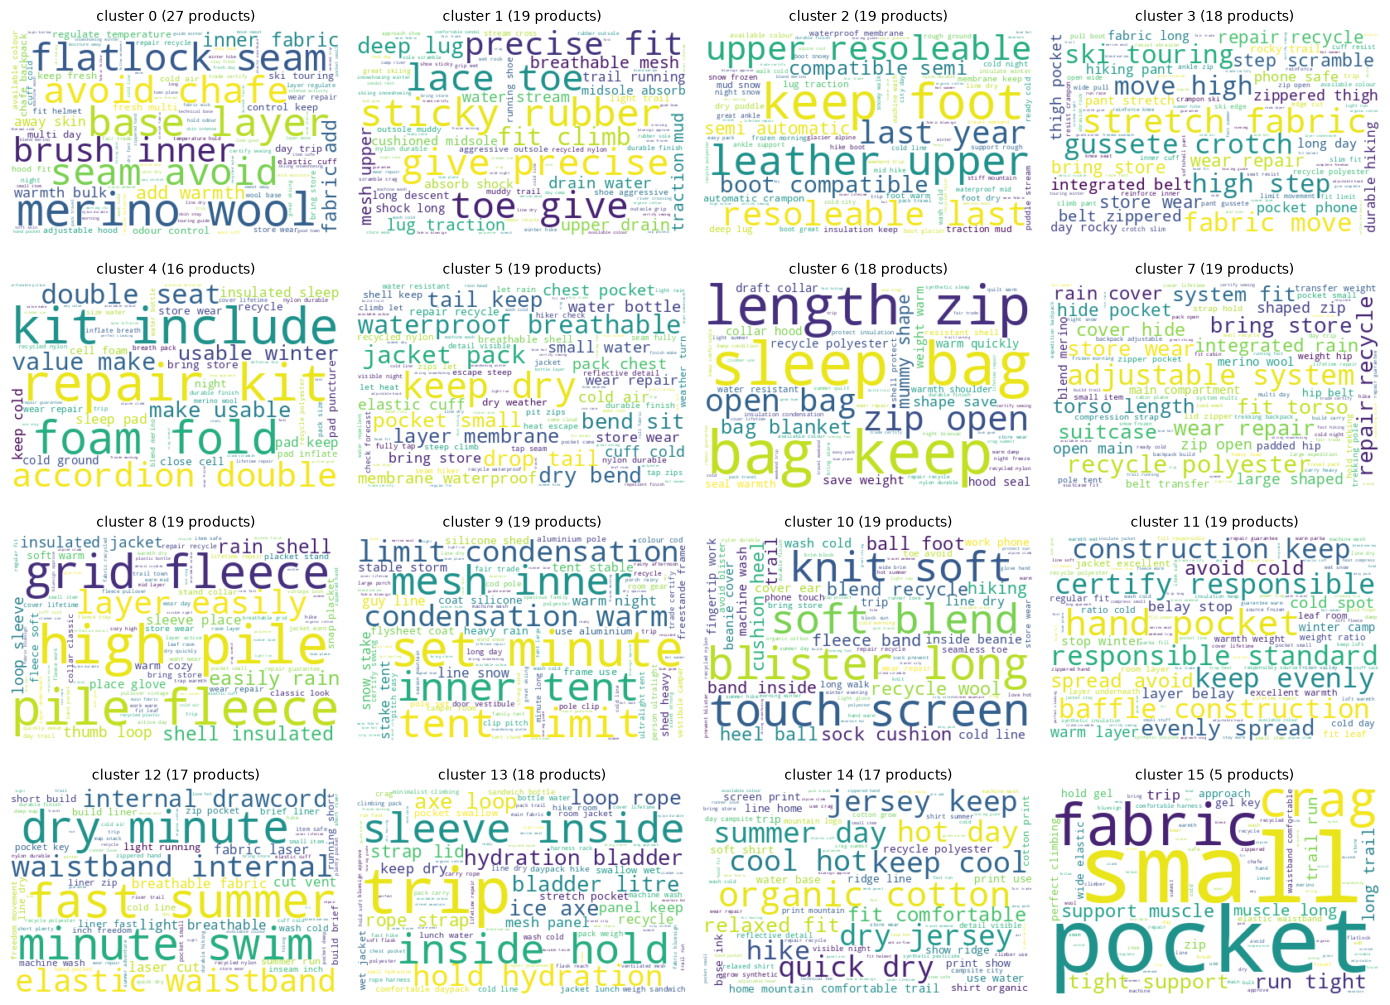

In [ ]:
def cloud(text, ax, title):
    wc = WordCloud(width=400, height=250, background_color="white", colormap="viridis", random_state=0).generate(text)
    ax.imshow(wc, interpolation="bilinear")
    ax.set_title(title, fontsize=10)
    ax.axis("off")

clusters = sorted(c for c in catalog.cluster.unique() if c >= 0)
n_cols = 4
fig, axes = plt.subplots(int(np.ceil(len(clusters) / n_cols)), n_cols, figsize=(14, 2.6 * np.ceil(len(clusters) / n_cols)))
for ax in axes.flat:
    ax.axis("off")
for ax, c in zip(axes.flat, clusters):
    part = catalog[catalog.cluster == c]
    cloud(" ".join(part["clean"]), ax, f"cluster {c} ({len(part)} products)")
plt.tight_layout()
plt.show()

In [ ]:
pd.crosstab(catalog["cluster"], catalog["category"])

category,Accessories,Bags,Bottoms,Camping,Footwear,Jackets,Tops
cluster,,,,,,,
-1,0,1,8,4,0,0,3
0,0,0,9,0,0,0,18
1,0,0,0,0,19,0,0
2,0,0,0,0,19,0,0
3,0,0,18,0,0,0,0
4,0,0,0,16,0,0,0
5,0,0,0,0,0,19,0
6,0,0,0,18,0,0,0
7,0,19,0,0,0,0,0


**What this shows:** each cluster has its own vocabulary, and almost every cluster falls inside a single category of the menu. But the clusters are **finer** than the categories: most categories are split into two or three clusters (for example, Camping into tents, sleeping bags and sleeping pads). Reading the word clouds, these clusters are **product types**. The noise products are the ones whose description mixes the vocabulary of several types.

## Part 2: recommender system

A first version: products of the same cluster. A better one ranks them by cosine similarity with the chosen product, and falls back on the most similar products of the whole catalogue when the product is noise.

In [ ]:
similarity = cosine_similarity(X)          # 304 x 304 matrix: similarity of every pair of products

def find_similar_items(item_id, n=5):
    """The n products most similar to item_id, from the same cluster when possible."""
    i = catalog.index[catalog["id"] == item_id][0]
    cluster = catalog.loc[i, "cluster"]
    candidates = catalog.index[(catalog["cluster"] == cluster) & (catalog.index != i)] if cluster >= 0 \
        else catalog.index[catalog.index != i]          # noise: search the whole catalogue
    best = sorted(candidates, key=lambda j: similarity[i, j], reverse=True)[:n]
    return catalog.loc[best, ["id", "name", "category"]].assign(similarity=similarity[i, best].round(2))

item = catalog.loc[catalog.name == "Ultralight Tent 2P", "id"].iloc[0]
print("Customer looks at:", catalog.loc[catalog.id == item, "name"].iloc[0])
find_similar_items(item)

Customer looks at: Ultralight Tent 2P


,id,name,category,similarity
75,76,Ultralight Tent 2P,Camping,0.61
278,279,Mountain Tent 3P,Camping,0.57
156,157,Mountain Tent 3P,Camping,0.55
267,268,Ultralight Tent 2P,Camping,0.53
47,48,Family Tent 4P,Camping,0.53


In [ ]:
noise_item = catalog.loc[catalog.cluster == -1, "id"].iloc[0]
print("Customer looks at:", catalog.loc[catalog.id == noise_item, "name"].iloc[0], "(a noise product)")
find_similar_items(noise_item)

Customer looks at: Running Tights (a noise product)


,id,name,category,similarity
238,239,Thermal Leggings,Bottoms,0.52
79,80,Men's Running Tights,Bottoms,0.51
274,275,Women's Running Tights,Bottoms,0.47
4,5,Men's Thermal Leggings,Bottoms,0.44
178,179,Women's Trail Running Shorts,Bottoms,0.36


Try it with other ids: `find_similar_items(42)`.

## Part 3: topic modeling with LSA

In [ ]:
svd = TruncatedSVD(n_components=6, random_state=0)
topics = svd.fit_transform(X)
for k, component in enumerate(svd.components_):
    top = words[np.argsort(component)[::-1][:10]]
    print(f"topic {k}: {', '.join(top)}")

topic 0: cold, recycle, dry, day, winter, pocket, repair, summer, warm, night
topic 1: summer, pocket, build, fast, trail, light, hot, run, short, elastic
topic 2: skin, layer, odour, fresh, merino, base, flatlock, chafe, ski, fabric
topic 3: bag, warm, fleece, jacket, shell, look, quickly, length, weight, collar
topic 4: tent, open, bag, summer, build, zip, large, system, length, pole
topic 5: crag, pad, recycle, foam, repair, approach, long, bring, store, summit


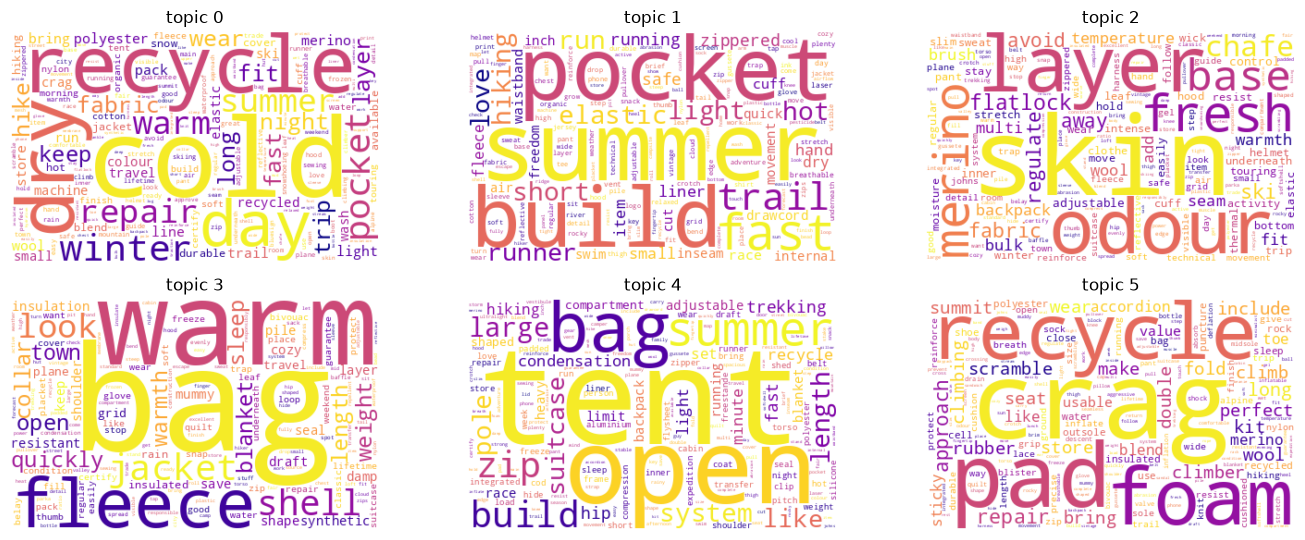

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(14, 5.5))
for k, ax in enumerate(axes.flat):
    weights = {w: v for w, v in zip(words, svd.components_[k]) if v > 0}
    wc = WordCloud(width=400, height=250, background_color="white", colormap="plasma",
                   random_state=0).generate_from_frequencies(weights)
    ax.imshow(wc, interpolation="bilinear")
    ax.set_title(f"topic {k}")
    ax.axis("off")
plt.tight_layout()
plt.show()

Topic 0 is the "average product": all the products have a positive coordinate on it (as in the topic modeling section). The other topics are more interesting: let's see which products are the strongest on each one, and how they spread over the categories.

In [ ]:
catalog["topic"] = topics[:, 1:].argmax(axis=1) + 1          # strongest topic, ignoring topic 0
pd.crosstab(catalog["topic"], catalog["category"])

category,Accessories,Bags,Bottoms,Camping,Footwear,Jackets,Tops
topic,,,,,,,
1,4,6,27,0,1,13,15
2,0,0,19,2,0,1,22
3,1,5,0,13,16,23,17
4,2,19,6,23,0,0,0
5,12,8,5,19,21,1,3


Because the data was created for this course, we have a file with the "true" product type and the activity theme of each description (a real company would not have it!). Let's use it to check what the clusters and topics captured.

In [ ]:
truth = pd.read_csv("data/cairn_outdoor_types.csv")
checked = catalog.merge(truth, on="id")

def purity(groups, labels):
    """Share of products that belong to the majority label of their group."""
    table = pd.crosstab(groups, labels)
    return table.max(axis=1).sum() / table.values.sum()

clustered = checked[checked.cluster >= 0]
print(f"Clusters vs product types: purity {purity(clustered.cluster, clustered.type):.2f}")
print(f"Clusters vs menu categories: purity {purity(clustered.cluster, clustered.category):.2f}")
print(f"Topics   vs activity themes: purity {purity(checked.topic, checked.theme):.2f}")
print(f"Topics   vs product types:   purity {purity(checked.topic, checked.type):.2f}")

Clusters vs product types: purity 0.97
Clusters vs menu categories: purity 0.97
Topics   vs activity themes: purity 0.45
Topics   vs product types:   purity 0.30


In [ ]:
pd.crosstab(checked["topic"], checked["theme"])

theme,climbing,running,travel,winter
topic,,,,
1,11,37,11,7
2,8,3,13,20
3,13,10,28,24
4,4,20,9,17
5,32,8,11,18


**What this shows:** topic 0 is the average product. Topic 2 gathers the base layers (merino, skin, odour: tops and leggings, like cluster 0), topic 4 the big gear (tents and trekking packs), topic 1 the light summer products (37 of its 66 products have the running theme) and topic 5 leans towards climbing (32 of its 69 products). The topics mix product types and activities: compared with the activity themes, they are only 45% pure, while the clusters match the product types at 97%.

## Conclusion and suggestions to the marketing team

- **Clusters = product types.** DBSCAN on the TF-IDF matrix finds almost pure groups, finer than the menu. Suggestion: add the product types as a second level of the menu, and create a **"Base layers"** category, today split between Tops and Bottoms.
- **Recommender.** Products of the same cluster, ranked by cosine similarity, give relevant suggestions (other tents for a tent). For noise products, the most similar products of the whole catalogue are a good fallback. A real system would also use what customers buy together, to suggest *complementary* products (a sleeping bag with a tent).
- **Topics ≠ clusters.** LSA topics are mixtures: some follow product families, others the activities (running and summer, climbing). They hint at another way to browse the shop, **"shop by activity"**, across the categories, but they are not clean enough to build it automatically: the team should define the activities, and use the topics to suggest which products belong to each.